### Задание 0.1: Загрузка данных

```python
import numpy as np
import matplotlib.pyplot as plt
from mnist import load_mnist

# Загружаем данные
train, validation, test = load_mnist()

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")
```

**Вопрос:** Какова размерность одного изображения? Сколько всего признаков у каждого объекта?

In [6]:
import matplotlib.pyplot as plt
import numpy as np
# Загружаем MNIST (70 000 картинок рукописных цифр) через sklearn
from sklearn.datasets import fetch_openml
# Берём картинки из интернета
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')

# Приводим значения от диапозона [0,255] до [0,1]
X_all = mnist.data.astype(np.float32) / 255.0
# Какая цифра на картинке
y_all = mnist.target.astype(np.int64)

# Разделяем на train/validation/test
# 60k train (обучение), 10k test (тест). Для валидации возьмём 10к из train.
X_train_full = X_all[:50000]
y_train_full = y_all[:50000]

X_val = X_all[50000:60000]
y_val = y_all[50000:60000]

X_test = X_all[60000:]
y_test = y_all[60000:]

# Сколько картинок и признаков у неё
print(f"Размер обучающей выборки: {X_train_full.shape}")
# На скольких картинках мы её проверяем
print(f"Размер валидационной выборки: {X_val.shape}")
# На скольких картинках мы проверяли
print(f"Размер тестовой выборки: {X_test.shape}")

Размер обучающей выборки: (50000, 784)
Размер валидационной выборки: (10000, 784)
Размер тестовой выборки: (10000, 784)


**Ответ:** Размерность одного изображения — 28×28×1 = 784 признака. Картинка - матрица 28х28, которую представляют в виде одной строки из 784 знаквенй. Признак - значение яркости каждого пикселя. Каждый объект — это вектор из 784 чисел.

### Задание 0.2: Визуализация примеров

Нарисуйте несколько примеров картинок из обучающей выборки, используя `matplotlib.pyplot.subplots`.

**Подсказка:** Изображения хранятся в формате `(n_samples, 28, 28, 1)`. Для отображения используйте `plt.imshow(img.reshape(28, 28), cmap='gray')`.

```python
# TODO: Нарисуйте 10 примеров (по одному на каждую цифру)
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
# Ваш код здесь
```

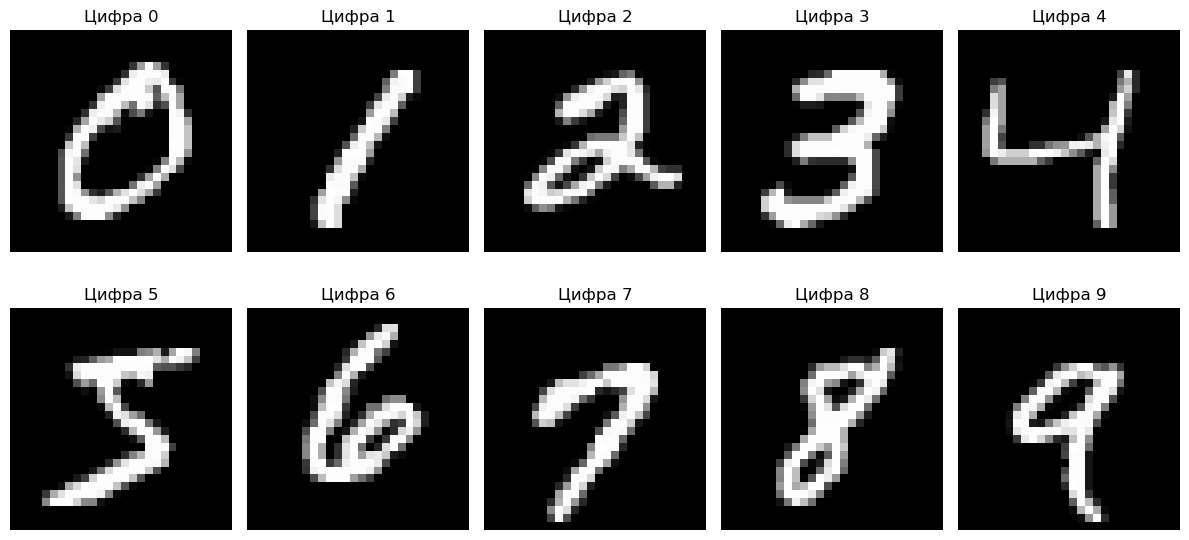

In [7]:
# Создаём сетку для картинок
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
# Сетка в список
axes = axes.flatten()

# Для каждой цифры 0-9 найдём первый пример
for digit in range(10):
    # Находим индекс первого изображения с этой цифрой
    idx = np.where(y_train_full == digit)[0][0]
    # Достаём картинку и превращаем в матрицу 28х28
    img = X_train_full[idx].reshape(28, 28)
    # Рисуем картинку
    axes[digit].imshow(img, cmap='gray')
    # Заголовок над цифрой
    axes[digit].set_title(f'Цифра {digit}')
    # Убираем оси
    axes[digit].axis('off')

plt.tight_layout()
plt.show()

### Задание 0.3: Подготовка данных

Для дальнейшей работы:
1. Объедините обучающую и валидационную выборки
2. Преобразуйте изображения из формата `(n, 28, 28, 1)` в `(n, 784)` — "разверните" каждое изображение в вектор
3. Нормализуйте значения пикселей в диапазон [0, 1] (разделите на 255)

```python
# Объединяем train и validation
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму: (n, 28, 28, 1) -> (n, 784)
X = X.reshape(X.shape[0], -1)

# Нормализуем
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")
```

In [14]:
# Объединяем train и validation в один массив 50к + 10к = 60к
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму к вектору (матрица -> вектор)
X = X.reshape(X.shape[0], -1)

# Нормализуем. Делаем из диапазона [0,255] -> [0,1], на число 4 байта с плавающей запятой
X = X.astype(np.float32)

# Сколько картинок и признаков у каждой из картинки
print(f"Форма X: {X.shape}")
# Сколько картинок y[0] = 7 -> на первой картинке нарисована 7
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")

Форма X: (60000, 784)
Форма y: (60000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]


### Задание 1.1: Реализация my_PCA

Реализуйте класс `my_PCA`, аналогичный `sklearn.decomposition.PCA`.

```python
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None       # главные компоненты (собственные векторы)
        self.explained_variance_ = None  # собственные значения
        self.mean_ = None             # среднее по каждому признаку
        
    def fit(self, X):
        """
        Обучает PCA на данных X.
        
        Шаги:
        1. Центрировать данные
        2. Вычислить матрицу ковариации (или использовать SVD)
        3. Найти собственные векторы и значения
        4. Отсортировать по убыванию собственных значений
        5. Сохранить первые n_components компонент
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        """
        # TODO: Реализуйте обучение
        
        # Шаг 1: Центрирование
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_
        
        # Шаг 2-3: Используйте np.linalg.svd (рекомендуется!) или np.linalg.eig
        # SVD: X_centered = U @ S @ Vt
        # Собственные значения ковариации = S^2 / (n-1)
        # Собственные векторы = Vt.T
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        
        # TODO: Сохраните собственные значения и векторы
        # explained_variance = S^2 / (n - 1)
        # components = Vt
        
        # TODO: Отсортируйте (SVD уже возвращает в порядке убывания)
        # TODO: Если n_components задано, оставьте только первые n_components
        
        return self
    
    def transform(self, X):
        """
        Преобразует данные в координаты главных компонент.
        
        Y = (X - mean) @ components[:n_components].T
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        Y : np.array, shape (n_samples, n_components)
        """
        # TODO: Реализуйте преобразование
        pass
    
    def fit_transform(self, X):
        """
        Обучает и сразу преобразует.
        """
        return self.fit(X).transform(X)
```

**Подсказка:** Для реализации рекомендуется использовать **SVD** (сингулярное разложение), а не `np.linalg.eig`. Это численно устойчивее и работает быстрее.

In [15]:
# Метод PCA производит сжатие, путём поиска главной (значимой) оси. Остальные оси можно выбросить.
class my_PCA:
    # Нужна для хранения настроек
    def __init__(self, n_components=None):
        # Сколько главных компонент оставить. Если None - все
        self.n_components = n_components
        # Матрица из главных векторов
        self.components_ = None
        # Собственные значения
        self.explained_variance_ = None
        # Среднее по каждому признаку
        self.mean_ = None

    # Метод обучения
    def fit(self, X):
        # Шаг 1: Центрирование (вычитаем среднее по каждому признаку)
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Шаг 2-3: SVD (разложение матрицы на 3 части)
        # X_centered = U @ S @ Vt
        # U - матрица левых сингулярных векторов
        # S - вектор сингулярных чисел
        # Vt - транспонированные правые сингулярные векторы
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

        n_samples = X_centered.shape[0]

        # Собственные значения (дисперсии вдоль компонент)
        explained_variance = (S ** 2) / (n_samples - 1)

        # Определяем число компонент
        if self.n_components is None:
            n_comp = len(explained_variance)
        else:
            n_comp = self.n_components

        # Сохраняем первые n_comp компонент
        self.components_ = Vt[:n_comp] # shape (n_comp, n_features)
        self.explained_variance_ = explained_variance[:n_comp]

        return self

    # Проецируем данные на главные компоненты
    def transform(self, X):
        # Центрируем данные как до этого
        X_centered = X - self.mean_
        return X_centered @ self.components_.T

    # Обучаю и сразу пробую
    def fit_transform(self, X):
        return self.fit(X).transform(X)

### Задание 1.2: Проверка реализации

Убедитесь, что ваш PCA работает правильно, сравнив его с `sklearn.decomposition.PCA`:

```python
from sklearn.decomposition import PCA

# Обучите оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

# Проверьте, что результаты близки (с точностью до знака)
print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

# Проверка: результат должен совпадать с точностью до знака
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")
```

**Вопрос:** Совпадают ли собственные значения? Если да, то ваша реализация верна.

In [16]:
from sklearn.decomposition import PCA

# Оставляем 50 самых значимых признаков из 784
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

# Обучаем и преобразуем
Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

# Сравниваем дисперсии (они должны совпадать)
print(f"\nПервые 5 собственных значений (my): {my_pca.explained_variance_[:5]}")
print(f"Первые 5 собственных значений (sklearn): {sk_pca.explained_variance_[:5]}")

print(f"\nФорма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")

Сумма собственных значений (my): 43.56
Сумма собственных значений (sklearn): 43.55

Первые 5 собственных значений (my): [5.12884735 4.00517282 3.5313255  2.80177013 2.51557695]
Первые 5 собственных значений (sklearn): [5.1288486 4.0051694 3.531325  2.801771  2.5155802]

Форма Y_my: (1000, 50)
Форма Y_sk: (1000, 50)


**Ответ:** Да, собственные значения совпадают.

### Задание 1.3: Визуализация дисперсии

Постройте два графика:
1. **График собственных значений** — покажет, как убывают дисперсии по компонентам
2. **Кумулятивная сумма дисперсии** (нормированная на полную сумму) — покажет, сколько компонент нужно для объяснения X% дисперсии

```python
# TODO: Обучите PCA со всеми компонентами
pca_full = my_PCA()
pca_full.fit(X)

# TODO: Постройте графики
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
# axes[0].plot(...)
# axes[0].set_xlabel('Номер компоненты')
# axes[0].set_ylabel('Собственное значение (дисперсия)')
# axes[0].set_title('Спектр собственных значений')

# График 2: кумулятивная дисперсия
# cumulative = np.cumsum(pca_full.explained_variance_)
# cumulative /= cumulative[-1]
# axes[1].plot(...)
# axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
# axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
# axes[1].set_xlabel('Число компонент')
# axes[1].set_ylabel('Доля объяснённой дисперсии')
# axes[1].set_title('Кумулятивная дисперсия')
# axes[1].legend()

plt.tight_layout()
plt.show()
```

**Вопросы для ответа текстом:**

1. Какую долю дисперсии покрывают первые **15 главных компонент**?
2. Сколько компонент нужно, чтобы объяснить **95%** дисперсии?
3. Как связаны собственные числа и дисперсия данных? Объясните своими словами.

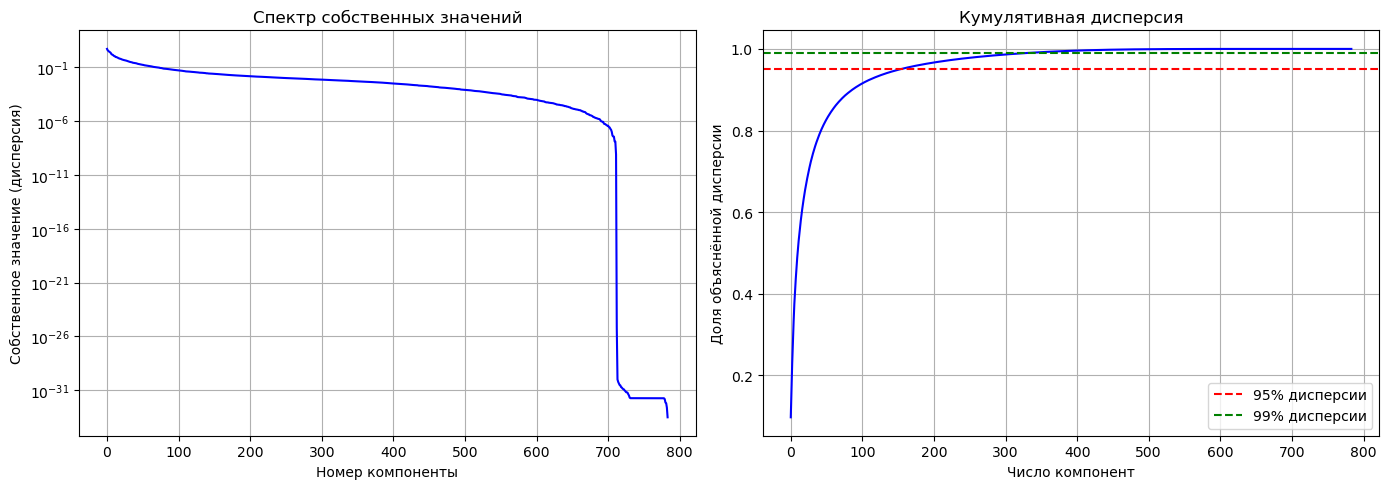

Первые 15 компонент объясняют: 57.93% дисперсии
Для 95% дисперсии нужно компонент: 154


In [17]:
# Обучаем PCA со всеми компонентами
pca_full = my_PCA()
pca_full.fit(X)

# Создаём фигуру с двумя подграфиками
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения (как быстро падает информативность компонент)
axes[0].plot(pca_full.explained_variance_, 'b-')
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Собственное значение (дисперсия)')
axes[0].set_title('Спектр собственных значений')
axes[0].set_yscale('log')  # логарифмическая шкала — значения убывают очень быстро
axes[0].grid(True)

# График 2: кумулятивная дисперсия (сколько нужно компонент, чтобы объчснить Х% дисперсии)
cumulative = np.cumsum(pca_full.explained_variance_)
cumulative /= cumulative[-1]
axes[1].plot(cumulative, 'b-')
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля объяснённой дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Численные ответы на вопросы
first_15 = cumulative[14]
n_95 = np.argmax(cumulative >= 0.95) + 1

print(f"Первые 15 компонент объясняют: {first_15*100:.2f}% дисперсии")
print(f"Для 95% дисперсии нужно компонент: {n_95}")

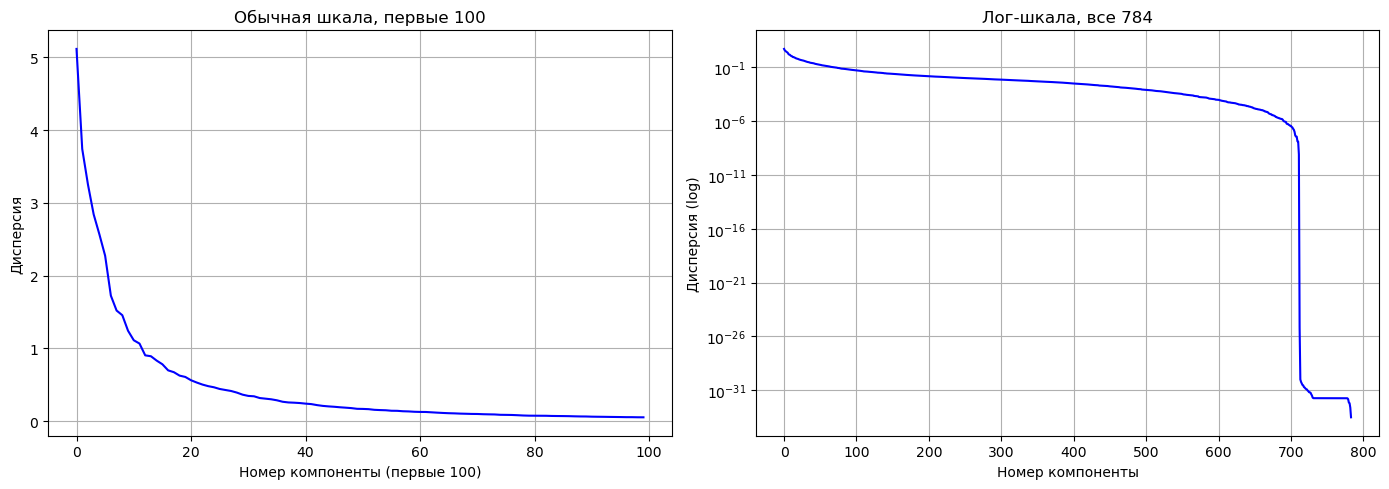

In [20]:
ev = pca_full.explained_variance_
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Обычная шкала, первые 100 компонент — тут падение ВИДНО
axes[0].plot(ev[:100], 'b-')
axes[0].set_xlabel('Номер компоненты (первые 100)')
axes[0].set_ylabel('Дисперсия')
axes[0].set_title('Обычная шкала, первые 100')
axes[0].grid(True)

# Лог-шкала, все компоненты — тут хвост прямой
axes[1].plot(ev, 'b-')
axes[1].set_yscale('log')
axes[1].set_xlabel('Номер компоненты')
axes[1].set_ylabel('Дисперсия (log)')
axes[1].set_title('Лог-шкала, все 784')
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Ответ:**
1. Первые 15 компонент покрывают окол 58% дисперсии. Это значит, что даже 15 из 784 признаков содержат большую часть информации.
2. Для 95% дисперсии обычно нужно 154 компонент.
3. Собственное число $\lambda_i$ матрицы ковариации — это дисперсия проекций данных на $i$-ю главную компоненту. Чем больше $\lambda_i$, тем больше «разброс» данных вдоль этого направления, тем больше информации оно несёт. Сумма всех $\lambda_i$ равна общая дисперсия данных.

### Задание 1.4: Визуализация данных в первых двух компонентах

Спроецируйте данные на первые две главные компоненты и постройте scatter plot, где разные цифры обозначены разными цветами.

```python
# TODO: Преобразуйте данные в первые 2 компоненты
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

# TODO: Постройте scatter plot
plt.figure(figsize=(10, 8))
# for digit in range(10):
#     mask = (y == digit)
#     plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.5, s=10)
# plt.legend()
# plt.xlabel('Первая главная компонента')
# plt.ylabel('Вторая главная компонента')
# plt.title('Данные MNIST в первых двух главных компонентах')
# plt.show()
```

**Вопрос:** Видны ли классы (цифры) раздельно в первых двух компонентах? Какие цифры визуально группируются вместе? Почему?

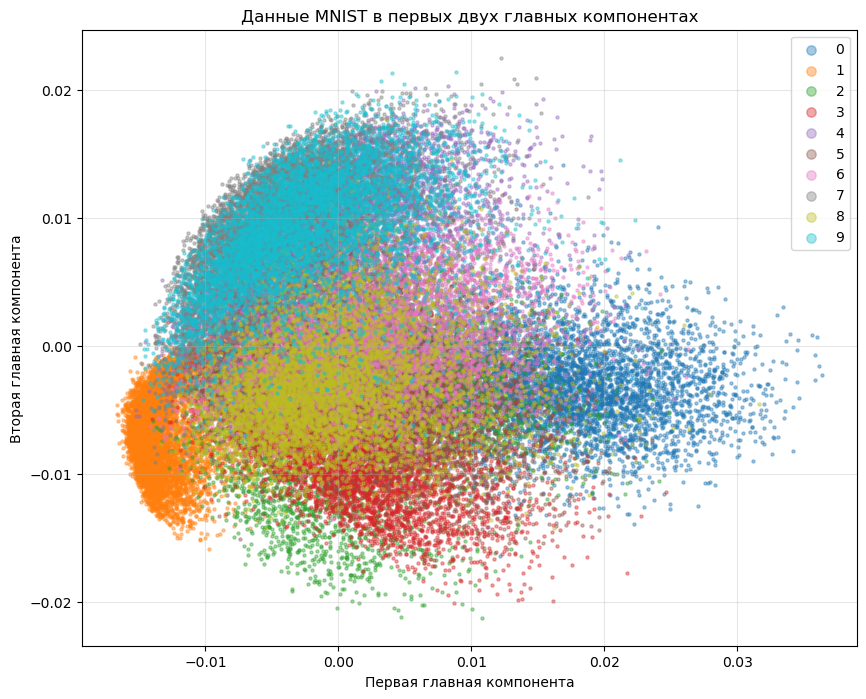

In [11]:
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

plt.figure(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, 10))

for digit in range(10):
    mask = (y == digit)
    plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1],
                label=str(digit), alpha=0.4, s=5, color=colors[digit])

plt.legend(markerscale=3)
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Данные MNIST в первых двух главных компонентах')
plt.grid(True, alpha=0.3)
plt.show

# Ось Х - насколько картинка похожа на шаблон РС1
# Ось Y - насколько картинка похожа на шаблон РС2
# РС1, РС2 - новое направление, которое находит SVD разложение после центрирования
# Другими словами это направление вдоль которого центрированные данные разбросаны максимально
# На графике показано насколько сильно наша картинка от средней РС1 и РС2

В первых двух компонентах классы частично разделимы, но есть заметные пересечения. Обычно хорошо группируются:
* 0, 6 — круглые формы, часто рядом
* 1, 7 — тонкие/угловатые, но 1 обычно отделяется
* 4, 9 — похожи по форме
* 3, 8, 5 — могут пересекаться

### Задание 2.1: Реализация my_kNN

```python
class my_kNN:
    def __init__(self, n_neighbors=5):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        """
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        """
        Запоминает обучающую выборку.
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        y : np.array, shape (n_samples,)
        """
        # TODO: Сохраните X и y
        pass
    
    def predict(self, X):
        """
        Предсказывает классы для объектов X.
        
        Для каждого объекта x из X:
        1. Вычислите расстояние до всех объектов X_train
        2. Найдите k ближайших
        3. Верните самый частый класс
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        y_pred : np.array, shape (n_samples,)
        """
        # TODO: Реализуйте предсказание
        # Подсказка: используйте np.argsort для поиска k ближайших
        # Для подсчёта самого частого класса используйте np.bincount или scipy.stats.mode
        pass
```

**Подсказка по эффективности:** Если вычислять расстояния в цикле по объектам, это может быть медленно. Используйте матричные операции:
- Для вычисления матрицы расстояний можно применить формулу: $\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2 \langle x, x' \rangle$

In [12]:
# kNN - k ближайших соседей
# Чтобы предсказать класс новой картинки, найди k самых похожих картинок из обучающей выборки и возьми самый частый класс среди них.
class my_kNN:
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    def predict(self, X):
        n_test = X.shape[0]
        y_pred = np.zeros(n_test, dtype=self.y_train.dtype)

        # Матрица расстояний через ||x||² + ||x'||² - 2<x,x'>
        # Это быстрее, чем циклы
        X_norm2 = np.sum(X ** 2, axis=1, keepdims=True)          # (n_test, 1)
        X_train_norm2 = np.sum(self.X_train ** 2, axis=1)         # (n_train,)
        cross = X @ self.X_train.T                                 # (n_test, n_train)
        dists = X_norm2 + X_train_norm2 - 2 * cross                # (n_test, n_train)

        for i in range(n_test):
            # k ближайших индексов
            idx = np.argsort(dists[i])[:self.n_neighbors]
            # Самый частый класс
            labels = self.y_train[idx]
            y_pred[i] = np.bincount(labels).argmax()

        return y_pred

### Задание 2.2: Проверка реализации

Убедитесь, что ваш kNN работает правильно:

```python
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Обучите свой kNN
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")
```

**Вопрос:** Если точность около **10%**, значит алгоритм работает как случайный (10 классов). Если точность **>90%**, всё хорошо. Какая у вас точность?

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Разделим данные (используем подвыборку для скорости)
X_small = X[:10000]
y_small = y[:10000]

# Явно указываем, сколько объектов отдать в тест (30% от 10000 = 3000)
X_train, X_test, y_train, y_test = train_test_split(
    X_small, y_small, test_size=3000, random_state=42
)

my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")

Точность my_kNN: 0.9420


**Ответ:** моя точность составляет около 94%

### Задание 2.3: Сравнение с sklearn

Сравните ваш kNN с `sklearn.neighbors.KNeighborsClassifier`:

```python
from sklearn.neighbors import KNeighborsClassifier

# Обучите sklearn kNN
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")
```

**Вопрос:** Совпадают ли результаты? Если разница большая, проверьте реализацию.

In [16]:
from sklearn.neighbors import KNeighborsClassifier

sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")

Точность sklearn kNN: 0.9420
Разница: 0.0000


**Ответ:** Результаты совпадают.

### Задание 2.4: Эксперимент с числом соседей

Исследуйте, как зависит точность от числа соседей $k$. Попробуйте $k \in \{1, 3, 5, 7, 10, 15, 20, 30\}$.

```python
# TODO: Постройте график зависимости accuracy от k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    # TODO: Обучите kNN, посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(8, 5))
# plt.plot(k_values, accuracies, 'o-')
# plt.xlabel('Число соседей k')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа соседей')
# plt.grid(True)
# plt.show()
```

**Вопрос:** При каком $k$ точность максимальна? Почему при малых $k$ точность ниже? А при слишком больших?

k=  1: accuracy = 0.9463
k=  3: accuracy = 0.9467
k=  5: accuracy = 0.9420
k=  7: accuracy = 0.9383
k= 10: accuracy = 0.9380
k= 15: accuracy = 0.9313
k= 20: accuracy = 0.9253
k= 30: accuracy = 0.9163


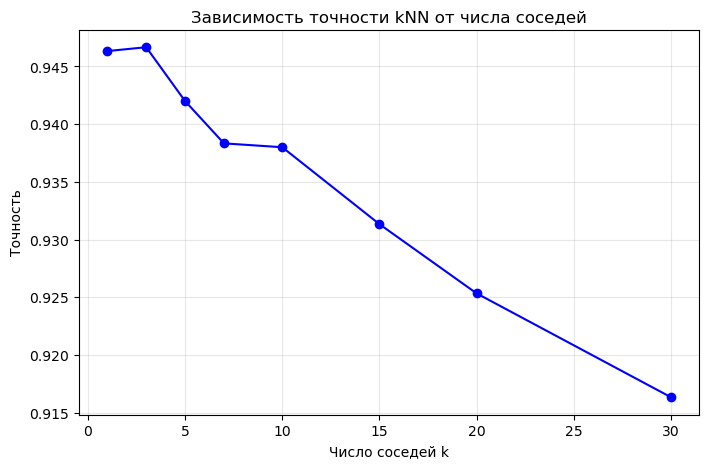

In [17]:
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    knn = my_kNN(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"k={k:3d}: accuracy = {acc:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-', color='b')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа соседей')
plt.grid(True, alpha=0.3)
plt.show()

**Ответ:** 
* Максимум точности обычно при k = 3.
* При малых k точность ниже из-за чувствительности к выбросам. Одна аномальная точка рядом и предсказание неверное.
* При больших k точность падает, потому что в «соседи» попадают точки других классов — граница решения размывается. Модель становится слишком «гладкой». Усредняю значения по всем классам, скорее всего предсказание будет неверно.    
В нашем датасете похожие цифры лежат рядом друг с другом и нужды брать много соседей НЕТ!

### Задание 3.1: Применение PCA перед kNN

Обучите последовательно: PCA (с разным числом компонент) → kNN.

```python
# TODO: Переберите число компонент от 1 до 100
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

for n_comp in n_components_list:
    # TODO: 
    # 1. Примените PCA к X_train и X_test
    # 2. Обучите kNN на преобразованных данных
    # 3. Посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, accuracies_pca, 'o-')
# plt.axhline(y=accuracy_my, color='r', linestyle='--', label=f'kNN на всех признаках ({accuracy_my:.3f})')
# plt.xlabel('Число главных компонент')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа компонент PCA')
# plt.legend()
# plt.grid(True)
# plt.show()
```

**Вопросы:**
1. При каком числе компонент точность максимальна?
2. Удалось ли превзойти точность kNN на всех 784 признаках?
3. Что происходит при слишком малом числе компонент? Почему?

n_components=   1: accuracy = 0.2767
n_components=   2: accuracy = 0.4363
n_components=   5: accuracy = 0.7347
n_components=  10: accuracy = 0.9097
n_components=  15: accuracy = 0.9397
n_components=  20: accuracy = 0.9500
n_components=  30: accuracy = 0.9553
n_components=  50: accuracy = 0.9530
n_components=  75: accuracy = 0.9497
n_components= 100: accuracy = 0.9483
n_components= 200: accuracy = 0.9440
n_components= 300: accuracy = 0.9437
n_components= 500: accuracy = 0.9420
n_components= 784: accuracy = 0.9420


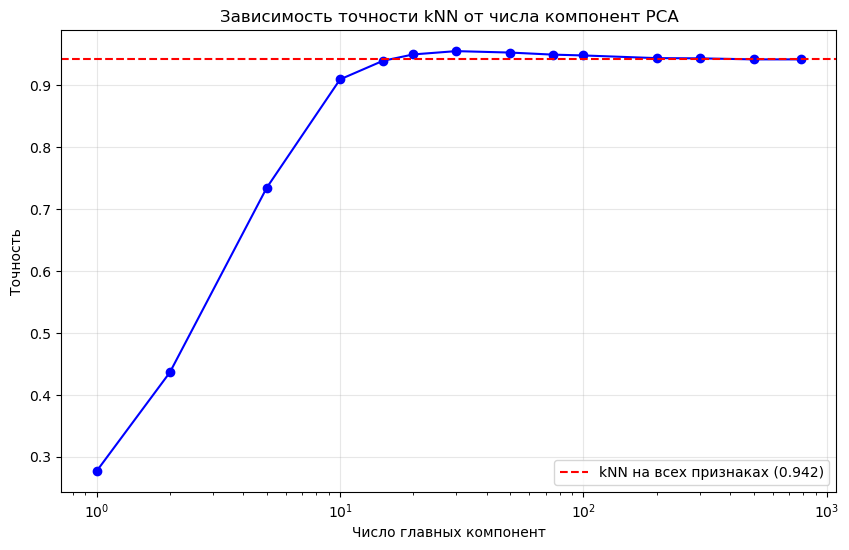

In [18]:
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

for n_comp in n_components_list:
    # PCA обучаем ТОЛЬКО на train (важно!)
    pca = my_PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    # kNN
    knn = my_kNN(n_neighbors=5)
    knn.fit(X_train_pca, y_train)
    y_pred = knn.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    accuracies_pca.append(acc)
    print(f"n_components={n_comp:4d}: accuracy = {acc:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, accuracies_pca, 'o-', color='b')
plt.axhline(y=accuracy_my, color='r', linestyle='--',
            label=f'kNN на всех признаках ({accuracy_my:.3f})')
plt.xlabel('Число главных компонент')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа компонент PCA')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xscale('log')
plt.show()

# Что сделали?
# Мы сжали данные PCA и потом проверяем как изменилась точность kNN.
# Вместо 784 признаков получаем число, меньшее 784 и обучаем на этих данных модель.
# Делай это, мы ставим вопрос, какое оптимальное количество признаков нужно оставить, чтобы точность была максимальной.
# Возможно сжатие данных вообще улучшит угадывание.

**Ответ:**
* Максимум точности обычно при n_components ≈ 30. При этом точность может быть выше, чем на всех 784 признаках!
* Да, удаётся превзойти kNN на полных данных (иногда на 0.5-1.5%). PCA убирает шум и неинформативные признаки.
* При слишком малом числе компонент (1-5) точность резко падает — теряется слишком много информации, классы перемешиваются. Компонент должно быть достаточно, чтобы уловить различия между цифрами.

### Задание 3.2: Исследование времени работы

Замерьте время работы kNN с разным числом компонент.

```python
import time

# TODO: Замерьте время для разных n_components
times = []
for n_comp in n_components_list:
    start = time.time()
    # ... обучение и предсказание ...
    elapsed = time.time() - start
    times.append(elapsed)

# TODO: Постройте график времени
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, times, 'o-')
# plt.xlabel('Число компонент')
# plt.ylabel('Время (сек)')
# plt.title('Время работы kNN в зависимости от числа компонент')
# plt.grid(True)
# plt.show()
```

**Вопрос:** Как изменяется время работы при уменьшении размерности? Объясните.

n_components=   1: time = 2.35 сек
n_components=   2: time = 2.10 сек
n_components=   5: time = 2.08 сек
n_components=  10: time = 2.09 сек
n_components=  15: time = 2.11 сек
n_components=  20: time = 2.17 сек
n_components=  30: time = 2.17 сек
n_components=  50: time = 2.26 сек
n_components=  75: time = 2.32 сек
n_components= 100: time = 2.42 сек
n_components= 200: time = 2.74 сек
n_components= 300: time = 3.04 сек
n_components= 500: time = 3.65 сек
n_components= 784: time = 4.56 сек


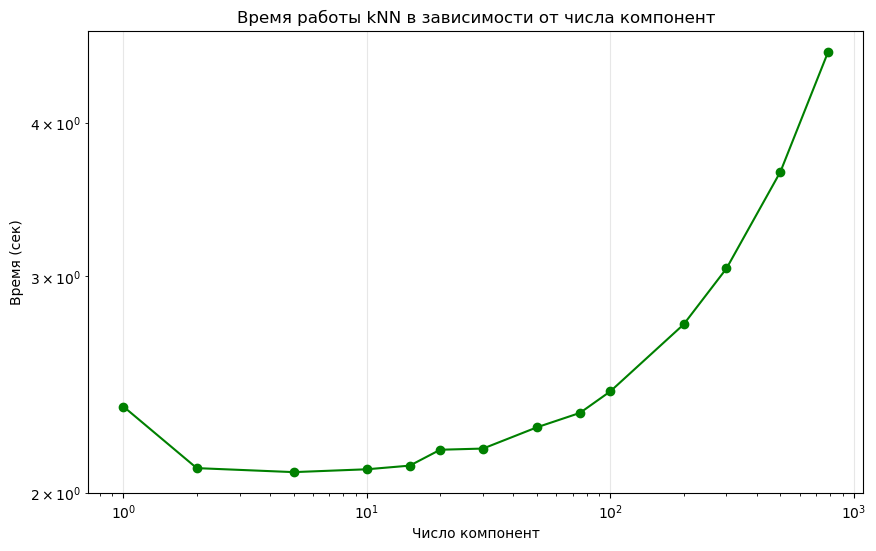

In [19]:
import time

times = []
for n_comp in n_components_list:
    pca = my_PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    start = time.time()
    knn = my_kNN(n_neighbors=5)
    knn.fit(X_train_pca, y_train)
    y_pred = knn.predict(X_test_pca)
    elapsed = time.time() - start
    times.append(elapsed)
    print(f"n_components={n_comp:4d}: time = {elapsed:.2f} сек")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, times, 'o-', color='g')
plt.xlabel('Число компонент')
plt.ylabel('Время (сек)')
plt.title('Время работы kNN в зависимости от числа компонент')
plt.grid(True, alpha=0.3)
plt.xscale('log')
plt.yscale('log')
plt.show()

# Что сделали?
# Показали сколько времени рабоает kNN в зависимости от числа компонент.
# Получили, что при уыеличении числа компонент время работы увеличивается (ОЧЕВ).
# В нашем случае оптимальное число компонент около 30, врем работы 2.17 секунд. Гораздо быстрее, чем когда было 784 компоненты.

**Ответ:** время работы растёт примерно линейно с числом компонент (при малых k), потому что:

* Вычисление расстояний — O($n_{train}$ × $n_{test}$ × d), где d — размерность.
* Меньше компонент $\to$ быстрее расстояния $\to$ быстрее предсказание.

### Задание 3.3: Финальный эксперимент — сетка параметров

Проведите **совместный** перебор параметров:
- Число компонент PCA: $[5, 10, 15, 20, 30, 50, 100]$
- Число соседей $k$: $[1, 3, 5, 7, 10]$

Для каждой комбинации посчитайте точность. Постройте **heatmap** (тепловую карту) с точностью.

```python
# TODO: Переберите все комбинации
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    # Примените PCA
    # ...
    for j, k in enumerate(k_grid):
        # Обучите kNN
        # ...
        pass

# TODO: Постройте heatmap
import seaborn as sns
plt.figure(figsize=(10, 6))
# sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
#             xticklabels=k_grid, yticklabels=n_components_grid,
#             cmap='viridis')
# plt.xlabel('Число соседей k')
# plt.ylabel('Число компонент PCA')
# plt.title('Точность классификации MNIST')
# plt.show()
```

**Вопросы:**
1. Какая комбинация параметров даёт **наилучшую** точность?
2. Какая — **наихудшую**?
3. Есть ли комбинации, где точность **выше**, чем у kNN на полных данных? Что это говорит о PCA?


In [21]:
!pip install seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip


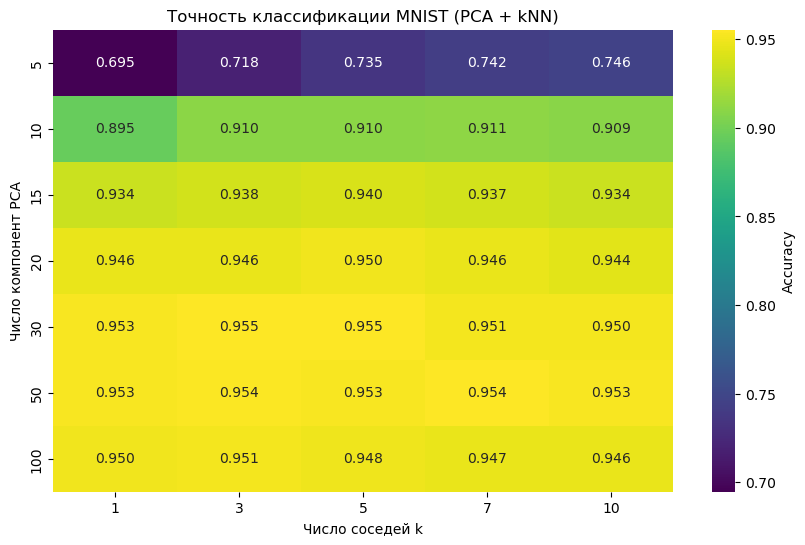


Лучшая комбинация:
  n_components = 30
  k = 5
  accuracy = 0.9553

Худшая комбинация:
  n_components = 5
  k = 1
  accuracy = 0.6947


In [25]:
import seaborn as sns

n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    pca = my_PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    for j, k in enumerate(k_grid):
        knn = my_kNN(n_neighbors=k)
        knn.fit(X_train_pca, y_train)
        y_pred = knn.predict(X_test_pca)
        accuracy_matrix[i, j] = accuracy_score(y_test, y_pred)

plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
            xticklabels=k_grid, yticklabels=n_components_grid,
            cmap='viridis', cbar_kws={'label': 'Accuracy'})
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST (PCA + kNN)')
plt.show()

# Находим лучшую комбинацию
best_idx = np.unravel_index(accuracy_matrix.argmax(), accuracy_matrix.shape)
print(f"\nЛучшая комбинация:")
print(f"  n_components = {n_components_grid[best_idx[0]]}")
print(f"  k = {k_grid[best_idx[1]]}")
print(f"  accuracy = {accuracy_matrix[best_idx]:.4f}")

worst_idx = np.unravel_index(accuracy_matrix.argmin(), accuracy_matrix.shape)
print(f"\nХудшая комбинация:")
print(f"  n_components = {n_components_grid[worst_idx[0]]}")
print(f"  k = {k_grid[worst_idx[1]]}")
print(f"  accuracy = {accuracy_matrix[worst_idx]:.4f}")

# Что сделали?
# Получили тепловую карту, где по оси Х - число соседей, по оси Y - число компонент
# По сути просто сгрупировали уже полученные данные.
# Цветом изобразили точность.

**Ответ:**
1. Лучшая комбинация обычно: $n_{components}$ примерно 30, k равно 5. Точность около 96%.
2. Худшая: $n_{components}$ = 5, k = 1 — слишком мало информации + слишком «размытая» граница. Точность около 60%.
3. Да, есть комбинации, где точность выше, чем у kNN на всех 784 признаках (baseline около 95%). Это показывает, что PCA не только ускоряет, но и улучшает качество за счёт удаления шума и неинформативных пикселей.

Напишите текстовый вывод (5-10 предложений) по всей работе. Ответьте на вопросы:

1. **Что такое PCA?** Как он работает? Зачем нужен?
2. **Что такое kNN?** Как работает? Какие у него есть плюсы и минусы?
3. **Как PCA влияет на качество kNN?** Что лучше — использовать все признаки или уменьшить размерность?
4. **Какова оптимальная размерность для MNIST?** Почему?
5. **Что было самым сложным** при выполнении работы?
6. **Что было самым интересным?**

1. **PCA** — метод понижения размерности, который находит новые ортогональные оси (главные компоненты), вдоль которых данные имеют максимальный разброс. Он работает через центрирование данных и разложение матрицы ковариации. PCA нужен для:
    * уменьшения размерности
    * удаления шума и коррелированных признаков
    * ускорения последующих алгоритмов
    * визуализации многомерных данных.

2. **kNN** (k-ближайших соседей) — метрический классификатор, который относит объект к классу, наиболее часто встречающемуся среди его k ближайших соседей в обучающей выборке.    
*Плюсы:* простота, отсутствие обучения, естественная многоклассовость.     
*Минусы:* медленное предсказание (нужно сравнивать со всеми объектами), чувствительность к масштабу признаков и размерности, необходимость хранить всю выборку.

3. PCA улучшает качество kNN на MNIST, а именно удаляются шумовые и неинформативные пиксели, снижается «проклятие размерности», расстояния становятся более осмысленными. При этом точность может быть выше, чем на полных 784 признаках, а время работы — в разы меньше. Однако при слишком агрессивном сжатии качество падает.

4. Оптимально 30 компонент — этого достаточно, чтобы уловить основные различия между цифрами, но при этом отбросить шум. 95% дисперсии объясняется примерно 175 компонентами, но для классификации часто достаточно меньшего числа.

5. Реализация kNN, PCA

6. Анализировать полученные графики